# Framing an 8-story hotel: steel I-beams + welds vs mass timber
### civil engineering from first principles -- section shape, the material ratio that pays, symmetry, orientation, and an inverse problem

Feynman's move: don't memorize the code book, ask **what the structure is trying to do**.
A floor beam is trying to sag; a column is trying to shorten; the whole building is trying
to slide and twist in wind and earthquakes. Every design rule below is just a way of
stopping one of those, derived in a line or two.

**The building:** an 8-story hotel with a 60 m × 18 m double-loaded-corridor floor plate,
3.3 m stories (H ≈ 26 m), and a column grid of about 7 m × 6 m. We frame it twice: once as
**steel** (wide-flange I-beams, welded moment connections, composite deck) and once as
**mass timber** (glulam beams and columns, CLT floor panels with a concrete topping
for acoustics, which a hotel needs).

All numbers are representative textbook values for learning, **not design values**.
Real design follows AISC 360 (steel), NDS (wood), ASCE 7 (loads) and the IBC. Module:
`dgs/building_framing.py`, tests: `tests/test_building_framing.py`.

In [1]:
import numpy as np, matplotlib.pyplot as plt
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))
from dgs import building_framing as bf
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
IN = 0.0254
W16 = bf.i_beam_section(15.7*IN, 5.50*IN, 0.345*IN, 0.250*IN)     # W16x26
W18 = bf.i_beam_section(17.7*IN, 6.00*IN, 0.425*IN, 0.300*IN)     # W18x35 (AISC Ix = 510 in^4)
for k, m in bf.MATERIALS.items():
    print(f"{k:12s} E = {m['E']/1e9:6.1f} GPa   F_allow = {m['F_allow']/1e6:6.1f} MPa   rho = {m['rho']:6.0f} kg/m^3")

steel_A992   E =  200.0 GPa   F_allow =  227.7 MPa   rho =   7850 kg/m^3
glulam_24F   E =   12.4 GPa   F_allow =   16.5 MPa   rho =    500 kg/m^3
clt          E =   11.0 GPa   F_allow =   10.0 MPa   rho =    480 kg/m^3
concrete     E =   30.0 GPa   F_allow =    0.0 MPa   rho =   2400 kg/m^3


## 1. Why an I? Bending stress lives at the edges

A bent beam stretches on one face and squashes on the other, and the strain grows
linearly with distance $y$ from the neutral axis. So the stress is $\sigma = My/I$, and the
beam's stiffness is the **second moment** $I=\int y^2\,dA$. That $y^2$ is the whole
story. Material near the middle contributes almost nothing, so you move it out to the
edges as **flanges** and keep only a thin **web** to hold them apart and carry shear.

For a wide flange (subtract the two empty rectangles beside the web from the bounding box):
$$I_x=\frac{b_f d^3-(b_f-t_w)(d-2t_f)^3}{12}$$

Our idealized W16×26 matches the AISC table (301 in⁴) to within the small fillet
radii we ignored.

W16x26  Ix =  294.2 in^4  (AISC 301)    Iy =  9.59 in^4  (AISC 9.59)
flanges hold 50% of the steel but 76% of the stiffness


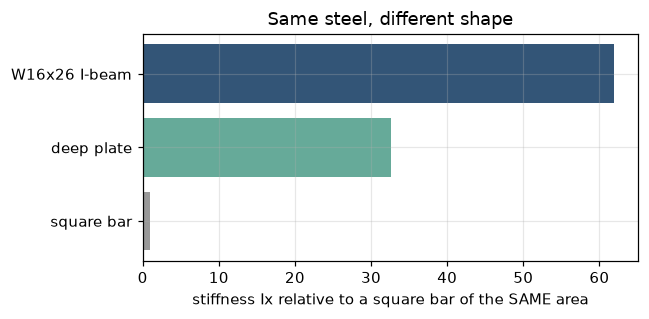

In [2]:
print(f"W16x26  Ix = {W16['Ix']/IN**4:6.1f} in^4  (AISC 301)    Iy = {W16['Iy']/IN**4:5.2f} in^4  (AISC 9.59)")
area_share = 2*W16['bf']*W16['tf']/W16['A']
print(f"flanges hold {area_share:.0%} of the steel but {bf.flange_share(W16):.0%} of the stiffness")

# same area, three shapes: square bar, deep rectangle, I-beam
A = W16["A"]
sq = bf.rect_section(np.sqrt(A), np.sqrt(A))
deep = bf.rect_section(A/W16["d"], W16["d"])
names, Is = ["square bar", "deep plate", "W16x26 I-beam"], [sq["Ix"], deep["Ix"], W16["Ix"]]
fig, ax = plt.subplots(figsize=(6, 3))
ax.barh(names, np.array(Is)/sq["Ix"], color=["#999", "#6a9", "#357"])
ax.set_xlabel("stiffness Ix relative to a square bar of the SAME area")
ax.set_title("Same steel, different shape"); plt.tight_layout(); plt.show()

### Orientation: the same beam on its side

Rotate the I by 90° and the flanges sit *on* the neutral axis, where they do nothing.
Deflection scales as $1/I$, so the weak-axis beam sags $I_x/I_y$ times more. That is why
beams are always installed web-vertical, and why a column's **weak axis** governs
buckling and gets braced first.

In [3]:
w, L = 10e3, 6.0          # 10 kN/m over a 6 m span
for ax_ in "xy":
    r = bf.check_beam("steel_A992", W16, w, L, axis=ax_)
    print(f"axis {ax_}: sigma = {r['sigma']/1e6:7.1f} MPa   delta = {r['delta']*1e3:7.1f} mm   "
          f"util(str) = {r['u_strength']:.2f}  util(defl) = {r['u_deflection']:.2f}  pass = {r['passes']}")
print(f"Ix/Iy = {W16['Ix']/W16['Iy']:.1f}  ->  weak-axis deflection is that many times larger")

axis x: sigma =    73.3 MPa   delta =     6.9 mm   util(str) = 0.32  util(defl) = 0.41  pass = True
axis y: sigma =   787.8 MPa   delta =   211.5 mm   util(str) = 3.46  util(defl) = 12.69  pass = False
Ix/Iy = 30.7  ->  weak-axis deflection is that many times larger


## 2. The floor beam: steel vs glulam

A typical hotel bay is a 7 m beam carrying a 3 m-wide strip of floor:
$w = (\text{dead}+\text{live})\times 3$ m. Hotel rooms are about 1.92 kPa live (40 psf).
Check two things:

* **strength**: $M=wL^2/8$, $\sigma=M/S\le F$
* **serviceability**: $\delta = \dfrac{5wL^4}{384EI}\le L/360$ (stops cracked finishes and bouncy floors)

Solving each for the depth of a $b$-wide rectangle gives
$h_\text{str}=\sqrt{6M/(Fb)}$ and $h_\text{def}=\left(\tfrac{60\,wL^3\cdot360}{384\,E\,b}\right)^{1/3}$.
Timber's $E$ is about 16× lower than steel's, so **wood is almost always
deflection-governed**. You buy depth, not strength. Steel at hotel spans often is too,
as the first trial below shows: a W16x26 fails $L/360$, so we go up a size.

steel  W16x26, w = 18.7 kN/m: util str 0.82, defl 1.23 -> deflection, pass=False
steel  W18x35, w = 18.7 kN/m: util str 0.54, defl 0.72 -> deflection, pass=True
glulam 215 mm wide, w = 14.8 kN/m: needs depth 474 mm (deflection-governed)


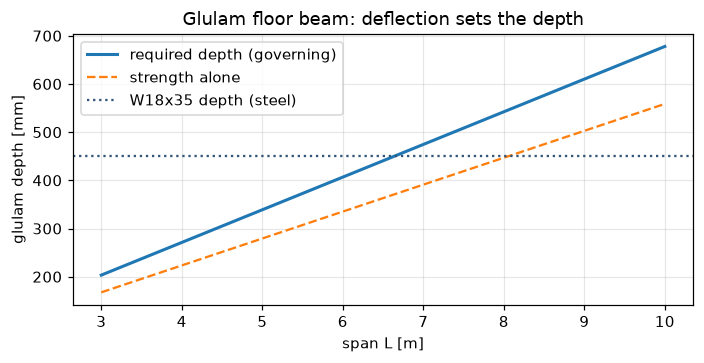

In [4]:
trib = 3.0
loads = {"steel": (4.3, 1.92), "timber": (3.0, 1.92)}     # kPa dead (incl. topping, finishes), live
w_steel = sum(loads["steel"]) * 1e3 * trib
w_tim = sum(loads["timber"]) * 1e3 * trib
L = 7.0
for name, sec_ in [("W16x26", W16), ("W18x35", W18)]:
    r = bf.check_beam("steel_A992", sec_, w_steel, L)
    print(f"steel  {name}, w = {w_steel/1e3:.1f} kN/m: util str {r['u_strength']:.2f}, defl {r['u_deflection']:.2f} -> {r['governs']}, pass={r['passes']}")
h, gov = bf.required_rect_depth("glulam_24F", 0.215, w_tim, L)
print(f"glulam 215 mm wide, w = {w_tim/1e3:.1f} kN/m: needs depth {h*1e3:.0f} mm ({gov}-governed)")

spans = np.linspace(3, 10, 60)
hs = np.array([bf.required_rect_depth("glulam_24F", 0.215, w_tim, s)[0] for s in spans])
hstr = np.sqrt(6*(w_tim*spans**2/8)/(bf.MATERIALS['glulam_24F']['F_allow']*0.215))
fig, ax = plt.subplots(figsize=(6.5, 3.4))
ax.plot(spans, hs*1e3, lw=2, label="required depth (governing)")
ax.plot(spans, hstr*1e3, "--", label="strength alone")
ax.axhline(W18["d"]*1e3, color="#357", ls=":", label="W18x35 depth (steel)")
ax.set_xlabel("span L [m]"); ax.set_ylabel("glulam depth [mm]"); ax.legend()
ax.set_title("Glulam floor beam: deflection sets the depth"); plt.tight_layout(); plt.show()

## 3. The ratio that pays: material indices

Here's the Feynman question: *for a beam that must reach a given stiffness, which material
gives the lightest (or cheapest) result?*

Fix the beam's width and let the depth $h$ float. Stiffness needs $EI\propto E h^3$ to be
constant, so $h\propto E^{-1/3}$ and the mass is $m\propto\rho h\propto \rho/E^{1/3}$.
The figure of merit is $E^{1/3}/\rho$. For a self-similar section it is $E^{1/2}/\rho$.
Divide by price per kg and you get stiffness **per dollar**.

The surprise is that steel and wood have nearly the **same** $E/\rho$. Wood wins the
beam indices because it is light, so it can afford to be deep. But the index assumes the
*same shape* for both materials. Steel gets rolled into an I, and that shape efficiency
(§1) wins back most of the gap: the sized beams end up with about the same mass per metre.
Material index × shape factor is the full story. The prices are editable placeholders,
so change them to your market's numbers and the ranking can flip.

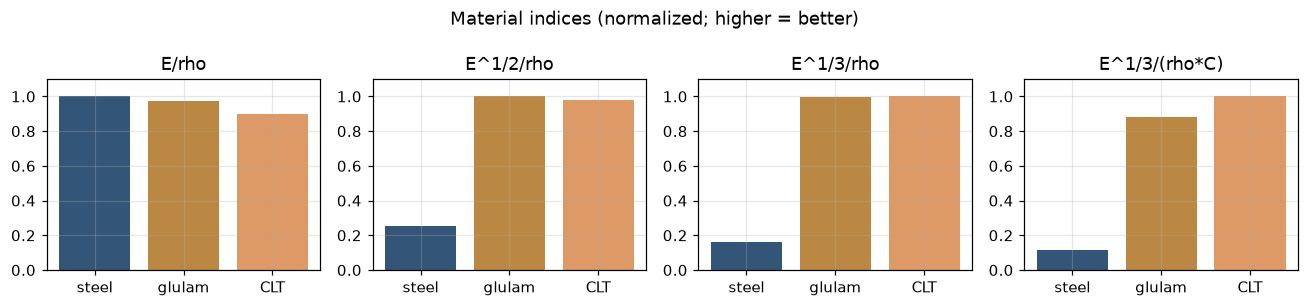

mass per metre:  W18x35 51 kg/m   glulam 215x474 51 kg/m
stiffness EI:    W18x35 42 MN.m^2   glulam 24 MN.m^2


In [5]:
mats = ["steel_A992", "glulam_24F", "clt"]
idx = {m: bf.material_indices(m) for m in mats}
keys = ["E/rho", "E^1/2/rho", "E^1/3/rho", "E^1/3/(rho*C)"]
fig, axs = plt.subplots(1, 4, figsize=(12, 2.8))
for a, k in zip(axs, keys):
    vals = [idx[m][k] for m in mats]
    a.bar(["steel", "glulam", "CLT"], np.array(vals)/max(vals), color=["#357", "#b84", "#d96"])
    a.set_title(k); a.set_ylim(0, 1.1)
fig.suptitle("Material indices (normalized; higher = better)"); plt.tight_layout(); plt.show()

# mass per metre of a beam that just meets the 7 m stiffness target
h_g, _ = bf.required_rect_depth("glulam_24F", 0.215, w_tim, L)
m_glulam = 0.215*h_g*bf.MATERIALS['glulam_24F']['rho']
m_steel = W18['A']*bf.MATERIALS['steel_A992']['rho']
print(f"mass per metre:  W18x35 {m_steel:.0f} kg/m   glulam 215x{h_g*1e3:.0f} {m_glulam:.0f} kg/m")
print(f"stiffness EI:    W18x35 {200e9*W18['Ix']/1e6:.0f} MN.m^2   glulam {12.4e9*0.215*h_g**3/12/1e6:.0f} MN.m^2")

## 4. Welding the moment connection

In a steel **moment frame**, the beam-to-column joint must transfer bending, not just
shear. The moment travels as a **force couple** in the flanges:
$F = M/(d-t_f)$, tension in one flange and compression in the other. Each flange is
fillet-welded to the column, and the weld's design strength per metre is

$$\phi R_n = 0.75 \times 0.6\,F_{EXX}\times 0.707\,a$$

where the throat is $0.707\,a$ for a 45° fillet with leg $a$. For an E70 electrode
($F_{EXX}$ = 482 MPa) this reproduces the AISC rule of thumb of
**1.392 kip/in per 1/16″ of leg**. In practice, seismic moment frames use complete-joint-penetration groove welds
at the flanges (post-Northridge 1994), so treat this as the statics, not the detailing.

Mass timber does this differently. Wood is not welded, and its joints are steel
**knife plates + dowels** or self-tapping screws. Timber frames therefore usually take
lateral load through **cores or braced frames**, not moment joints. See §6.

In [6]:
M_beam = w_steel*L**2/8          # midspan gravity moment as a stand-in for the joint's design moment
legs = np.array([5, 6, 8, 10, 12])*1e-3
for a in legs:
    c = bf.moment_connection_weld(M_beam, W18, a)
    print(f"leg {a*1e3:4.0f} mm: flange force {c['flange_force']/1e3:6.1f} kN, need {c['L_required']*1e3:5.0f} mm "
          f"of weld, have {c['L_available']*1e3:.0f} mm (both sides) -> fits={c['fits']}")

leg    5 mm: flange force  260.5 kN, need   340 mm of weld, have 305 mm (both sides) -> fits=False
leg    6 mm: flange force  260.5 kN, need   283 mm of weld, have 305 mm (both sides) -> fits=True
leg    8 mm: flange force  260.5 kN, need   212 mm of weld, have 305 mm (both sides) -> fits=True
leg   10 mm: flange force  260.5 kN, need   170 mm of weld, have 305 mm (both sides) -> fits=True
leg   12 mm: flange force  260.5 kN, need   142 mm of weld, have 305 mm (both sides) -> fits=True


## 5. Eight stories of gravity, and why weight attracts earthquakes

Follow the load down an interior column. Each floor adds its tributary area
(here 7 × 6 = 42 m²) times the factored load $1.2D+1.6L$. The live load gets reduced
because it's unlikely every floor is fully loaded at once (ASCE 7:
$0.25+4.57/\sqrt{K_{LL}A_T}$, never below 0.4).

The equivalent-lateral-force method sets the seismic base shear at $V=C_sW$, where $W$ is
the building's **weight**. A lighter mass-timber frame therefore attracts proportionally less
earthquake force. That benefit runs through the whole design: smaller columns,
smaller foundations, less lateral system.

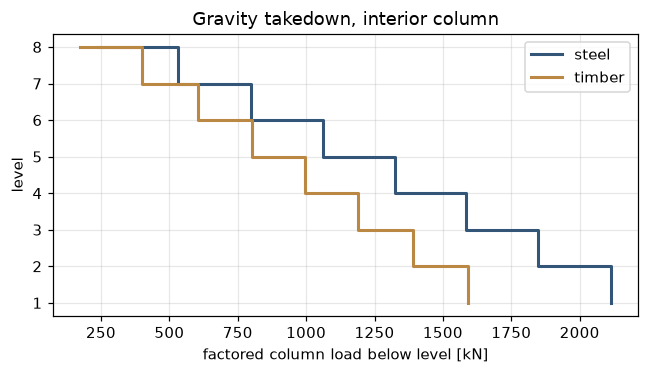

steel : base column   2116 kN   seismic weight  37.2 MN   base shear 3.72 MN
timber: base column   1592 kN   seismic weight  25.9 MN   base shear 2.59 MN


In [7]:
n, At, A_floor = 8, 42.0, 60*18
P = {k: bf.gravity_takedown(n, At, d, l) for k, (d, l) in loads.items()}
fig, ax = plt.subplots(figsize=(6, 3.5))
levels = np.arange(n, 0, -1)
for k, c in [("steel", "#357"), ("timber", "#b84")]:
    ax.step(P[k]/1e3, levels, where="post", lw=2, color=c, label=k)
ax.set_xlabel("factored column load below level [kN]"); ax.set_ylabel("level")
ax.legend(); ax.set_title("Gravity takedown, interior column"); plt.tight_layout(); plt.show()
for k, (d, _) in loads.items():
    s = bf.seismic_base_shear(A_floor, n, d, Cs=0.10)
    print(f"{k:6s}: base column {P[k][-1]/1e3:6.0f} kN   seismic weight {s['W']/1e6:5.1f} MN   base shear {s['V']/1e6:4.2f} MN")

## 6. Symmetry and orientation: don't let the building twist

**Symmetry.** Lateral force acts at the floor's **center of mass**. The walls, cores and
braces resist it at the **center of rigidity**, $x_{cr}=\sum k_ix_i/\sum k_i$. If the two
centers don't coincide, the eccentricity $e=x_{cm}-x_{cr}$ creates a torsion $T=Ve$ that
overloads the elements on one side. Hotels put the elevator/stair core where the
corridor and lobby want it, which is often at one end. The sweep below shows the cost
of that choice in torsion.

**Orientation.** Wind force is $F=q\,C_d\,B\,H$ with $q=\tfrac12\rho v^2$, so it is
proportional to the **width of the face the wind hits**. A 60 × 18 m slab sees
60/18 ≈ 3.3× more force on its broad face, and that is also the direction in which its plan is
least deep to resist overturning. That's why you check both directions and align the
broad face with site constraints and the prevailing wind.

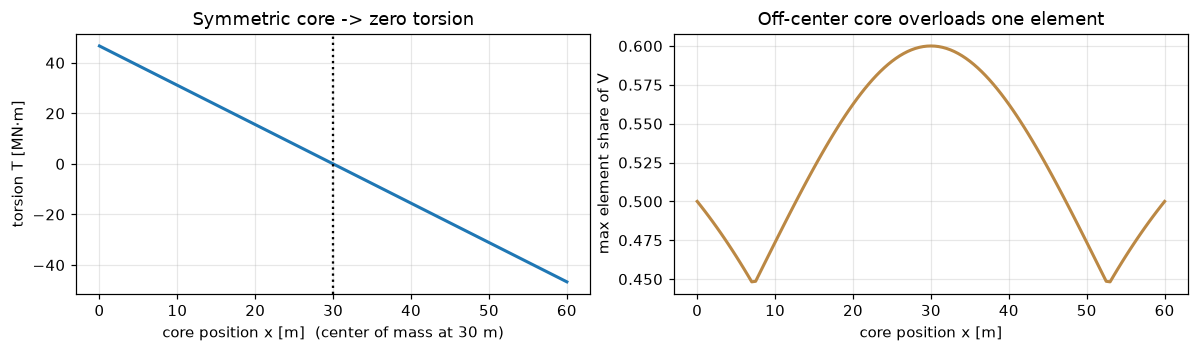

wind on broad 60 m face: F = 2.02 MN, overturning  26.6 MN·m
wind on narrow 18 m face: F = 0.61 MN, overturning   8.0 MN·m


In [8]:
V = bf.seismic_base_shear(A_floor, n, loads["timber"][0], 0.10)["V"]
# end shear walls at x=0 and x=60 (stiffness 1 each) + one stiff core (stiffness 3) placed at x_c
xc = np.linspace(0, 60, 121)
T = [bf.torsional_eccentricity([0, xc_, 60], [1, 3, 1], x_cm=30.0, V=V)["T"] for xc_ in xc]
Vmax = [bf.torsional_eccentricity([0, xc_, 60], [1, 3, 1], x_cm=30.0, V=V)["V_walls"].max() for xc_ in xc]
fig, axs = plt.subplots(1, 2, figsize=(11, 3.3))
axs[0].plot(xc, np.array(T)/1e6, lw=2); axs[0].axvline(30, ls=":", c="k")
axs[0].set_xlabel("core position x [m]  (center of mass at 30 m)"); axs[0].set_ylabel("torsion T [MN·m]")
axs[0].set_title("Symmetric core -> zero torsion")
axs[1].plot(xc, np.array(Vmax)/V, lw=2, c="#b84")
axs[1].set_xlabel("core position x [m]"); axs[1].set_ylabel("max element share of V")
axs[1].set_title("Off-center core overloads one element"); plt.tight_layout(); plt.show()

H = n*3.3
for face, B in [("broad 60 m face", 60), ("narrow 18 m face", 18)]:
    f = bf.wind_force(40.0, B, H)
    print(f"wind on {face}: F = {f['F']/1e6:4.2f} MN, overturning {f['M_overturn']/1e6:5.1f} MN·m")

## 7. AI physics: the inverse problem

Everything above is the **forward model** (load → deflection). Engineers also run
it backwards. When you load-test a delivered glulam beam and measure its sag, you can ask
what its real modulus is. The deflection is **linear in the compliance $u=1/E$**:
$\delta_i = a_i\,u$ with $a_i=5w_iL^4/(384I)$, so least squares gives the answer in one line.

Solve the same thing by **gradient descent** on the squared error and you get exactly what a
neural net's training loop does, with a single physics-informed parameter. It is the same
forward-model/inverse-problem structure as the phase retrieval in this repo: we know
the physics $H(f)$ and fit the unknowns to the measurements.

least squares:    E = 12.30 GPa (true 12.4)  rms residual 0.08 mm
gradient descent: E = 12.30 GPa after 60 steps


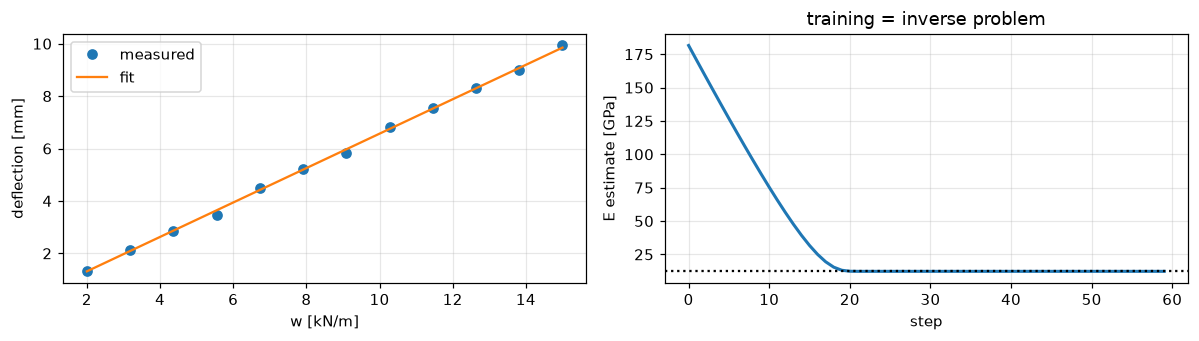

In [9]:
rng = np.random.default_rng(1)
sec = bf.rect_section(0.215, 0.6)
E_true, Lt = 12.4e9, 7.0
w_test = np.linspace(2e3, 15e3, 12)
a = 5*w_test*Lt**4/(384*sec["Ix"])
d_meas = a/E_true*(1 + 0.03*rng.standard_normal(w_test.size))      # 3% gauge noise
fit = bf.fit_modulus(w_test, d_meas, Lt, sec["Ix"])
print(f"least squares:    E = {fit['E']/1e9:.2f} GPa (true {E_true/1e9})  rms residual {fit['rms']*1e3:.2f} mm")

# the same fit as a 'training loop' (gradient descent on log E)
logE, lr, hist = np.log(5e9), 0.5, []
for step in range(60):
    pred = a*np.exp(-logE)
    loss = np.mean((pred - d_meas)**2)
    grad = np.mean(2*(pred - d_meas)*(-pred))                  # d loss / d logE
    logE -= lr*grad/np.mean(d_meas**2)
    hist.append(np.exp(logE)/1e9)
print(f"gradient descent: E = {hist[-1]:.2f} GPa after {len(hist)} steps")
fig, axs = plt.subplots(1, 2, figsize=(11, 3.2))
axs[0].plot(w_test/1e3, d_meas*1e3, "o", label="measured")
axs[0].plot(w_test/1e3, a/fit["E"]*1e3, "-", label="fit")
axs[0].set_xlabel("w [kN/m]"); axs[0].set_ylabel("deflection [mm]"); axs[0].legend()
axs[1].plot(hist, lw=2); axs[1].axhline(E_true/1e9, ls=":", c="k")
axs[1].set_xlabel("step"); axs[1].set_ylabel("E estimate [GPa]"); axs[1].set_title("training = inverse problem")
plt.tight_layout(); plt.show()

## Takeaways

1. **Shape beats material.** $I=\int y^2dA$ is why I-beams exist and why they must be
   installed web-vertical: the strong/weak axis ratio is about 30× for a W16.
2. **At hotel spans, deflection governs both materials.** The W16 passed strength but failed
   $L/360$. Timber needs about 2× the steel's depth, which costs floor-to-floor height in a 3.3 m story.
3. **The ratio that pays is material index × shape.** Wood wins $E^{1/3}/\rho$, steel wins
   on shape (the I), and the sized beams come out at about equal mass per metre. The cost
   comparison then rests on price per kg and labor (field welding vs. fast CLT erection).
4. **Welds turn moments into a flange force couple.** Steel can make rigid moment
   frames. Timber connects with knife plates and screws and resists lateral load with cores.
5. **Weight attracts earthquakes** ($V=C_sW$), so a lighter timber frame means smaller
   base shear and foundations.
6. **Symmetry kills torsion** (put the core at the center of mass), and **orientation** sets
   wind force (the broad face takes ~3× the load).
7. **Inverse problems** fit material properties to test data. That is the same loop as ML training and as
   the phase retrieval in this repo.

**Not covered (all real constraints in an 8-story timber hotel):** fire rating and char
depth (2021 IBC Types IV-A/B/C), acoustic separation between rooms, floor vibration,
moisture and shrinkage at connections, and lateral drift limits. Pick any of these as a follow-up.